## Упражнения  

1. Выбрать и скачать один из наборов данных с сайта [timeseriesclassification](https://www.timeseriesclassification.com/dataset.php). 

    Подробнее о датасетах, их форматах, и как их скачивать - [Ноутбук](https://github.com/aeon-toolkit/aeon/blob/main/examples/datasets/data_loading.ipynb)

2.  Записать название выбранного датасета в таблицу. Помните - совпадений быть не должно. Каждый работает с уникальным датасетом. Этот датасет вам понадобиться в лабе 14 (aeon) и лабе 16 (tslean)

3. Проанализировать датасет

4. Найти шейплеты для классов в датесете

5. Провести классификацию на основе шейплетов.

Датасет: ItalyPowerDemand

In [12]:
import matplotlib.pyplot as plt
from aeon.datasets import load_classification
from sklearn.linear_model import RidgeClassifierCV
from aeon.classification.shapelet_based import ShapeletTransformClassifier, RDSTClassifier
from aeon.visualisation import ShapeletClassifierVisualizer

X_train, y_train = load_classification("ItalyPowerDemand", split='train')
X_test, y_test = load_classification("ItalyPowerDemand", split='test')

ShapeletTransform accuracy: 0.956268221574344


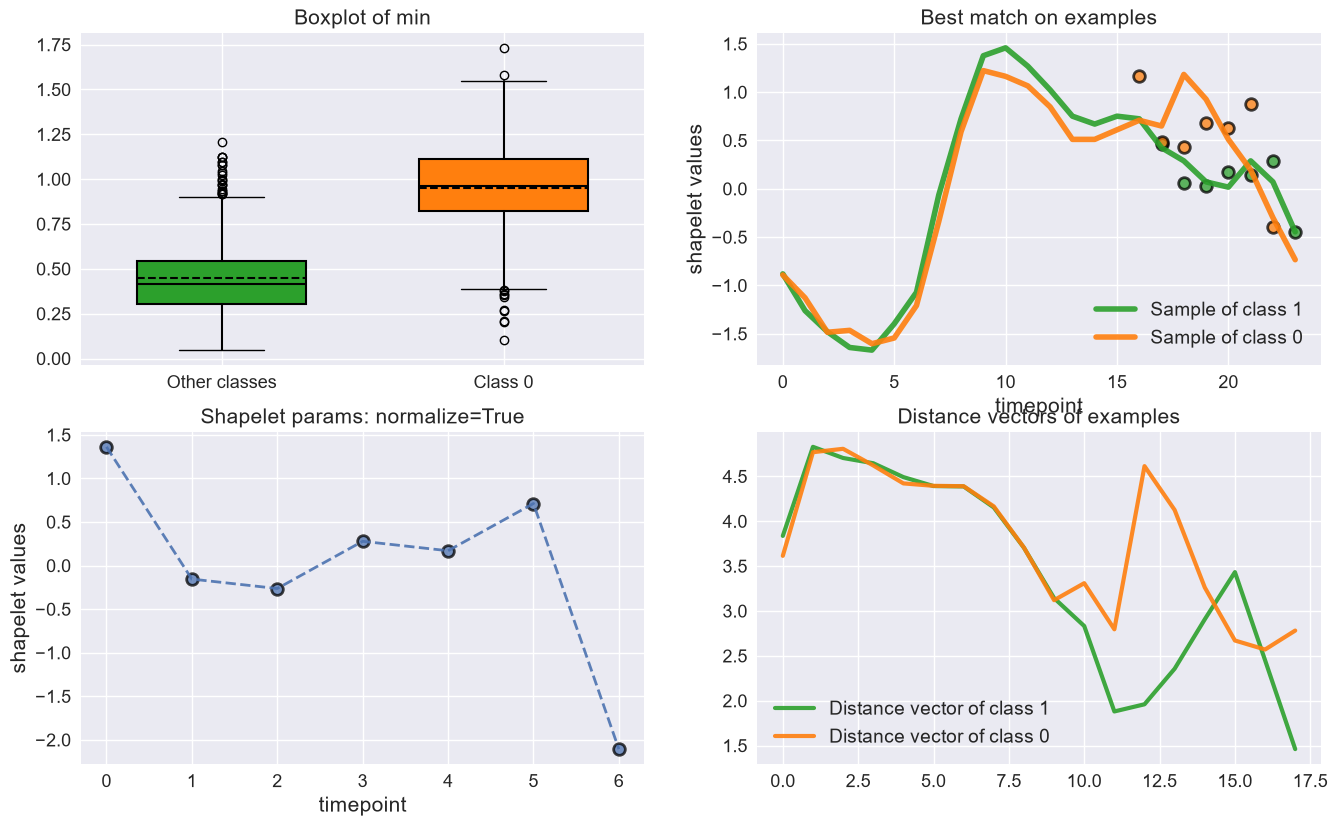

RDST accuracy: 0.8794946550048591


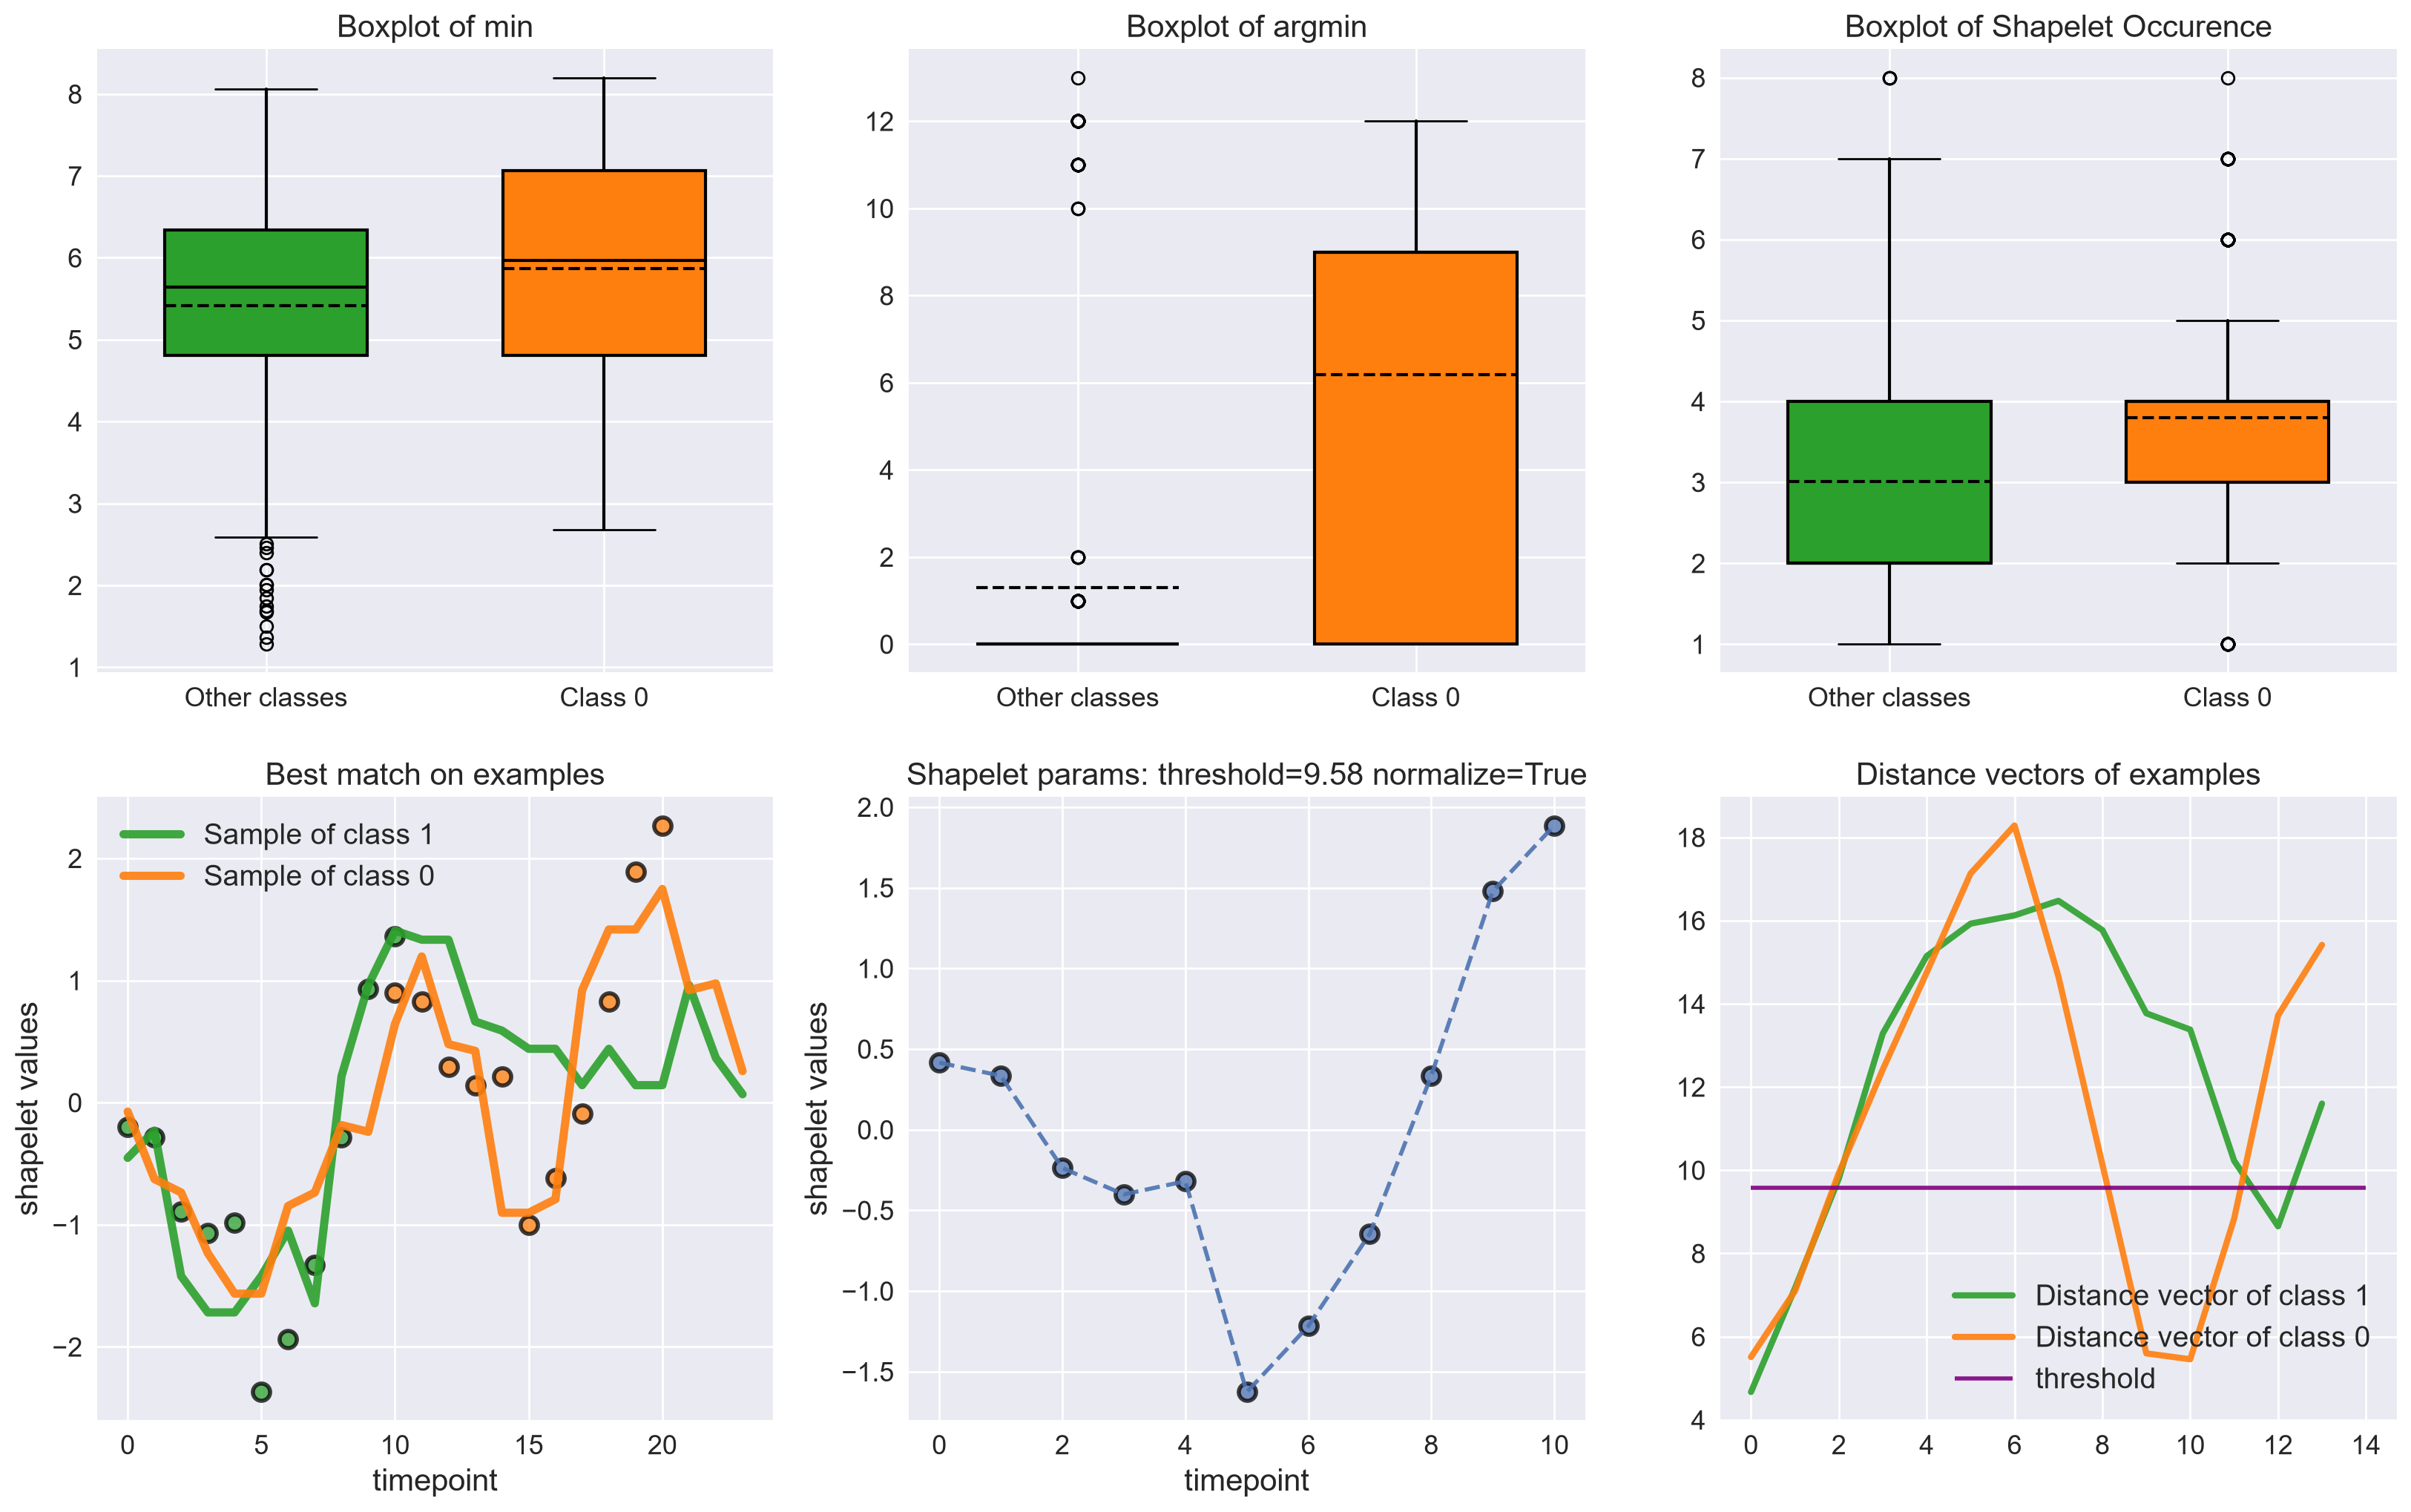

In [10]:
# ShapeletTransformClassifier – без явного max_shapelet_length
stc = ShapeletTransformClassifier(estimator=RidgeClassifierCV(), random_state=42)
stc.fit(X_train, y_train)
print(f"ShapeletTransform accuracy: {stc.score(X_test, y_test)}")

# Визуализация
stc_vis = ShapeletClassifierVisualizer(stc)
stc_vis.visualize_shapelets_one_class(X_test, y_test, 0, figure_options={"figsize": (16,9.5), "nrows":2, "ncols":2})
plt.show()

# RDSTClassifier
rdst = RDSTClassifier(random_state=42)
rdst.fit(X_train, y_train)
print(f"RDST accuracy: {rdst.score(X_test, y_test)}")

rdst_vis = ShapeletClassifierVisualizer(rdst)
rdst_vis.visualize_shapelets_one_class(X_test, y_test, 0)
plt.show()